# 01 — Conhecer e validar os dados

**Nossa história:** uma fintech usa um modelo de crédito e precisa acompanhar
mudanças nos clientes. Primeiro, vamos entender quais dados entram nesse modelo
e quais condições eles devem cumprir.

**01 Dados e qualidade → 02 Modelo de referência → 03 Mudança e monitoramento.**

Execute as células de cima para baixo no ambiente do projeto ou no Docker.
Este notebook mantém os dados apenas em memória e preserva os CSVs de origem.


## 1. De onde vêm os dados?

Usamos dois arquivos do Home Credit em `data/raw/home-credit-default-risk/`:
`application_train.csv` contém as solicitações e
`HomeCredit_columns_description.csv` explica suas colunas.

Para uma demonstração rápida, selecionamos **20 mil solicitações e dez variáveis**.
A amostra usa seed 42 e preserva aproximadamente a proporção de cada classe do alvo.


In [1]:
import sys
from pathlib import Path

from IPython.display import display

project_root = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(project_root))

from ml_prep_kit import (
    CSVDataLoader,
    DataValidator,
    HomeCreditData,
    VisualizationReporter,
)

In [2]:
loader = CSVDataLoader(project_root / "data/raw/home-credit-default-risk")
preparation = HomeCreditData(sample_size=20_000, random_state=42)
validator = DataValidator()
reporter = VisualizationReporter()

raw_df = loader.load(
    {"solicitacoes": "application_train.csv"},
    read_csv_kwargs={"usecols": preparation.source_columns},
)["solicitacoes"]
sample_df = preparation.sample(raw_df)
tables = {"origem": raw_df, "amostra": sample_df}
display(validator.summarize(tables).drop(columns="memory_mb"))

,dataset,rows,columns
0,origem,307511,12
1,amostra,20000,12


In [3]:
dictionary = loader.load(
    {"dicionario": "HomeCredit_columns_description.csv"},
    read_csv_kwargs={"encoding": "cp1252"},
)["dicionario"]
feature_dictionary = validator.select_dictionary(
    dictionary, preparation.source_columns, table_pattern="application_{"
)

## 2. O que queremos prever?

`TARGET = 1` indica dificuldade de pagamento; `0` representa os demais casos.
A documentação não informa os limites de dias e parcelas usados para formar o alvo.
Por isso, não o interpretamos como inadimplência em 30 ou 90 dias.

Escolhemos um recorte pequeno e interpretável para estudar mudanças de perfil:

| Grupo | Variáveis utilizadas |
|---|---|
| Perfil | Idade, número de filhos, tipo de renda, escolaridade e moradia |
| Solicitação | Renda, valor do crédito e anuidade |
| Patrimônio declarado | Posse de carro e de imóvel |

`SK_ID_CURR` identifica a solicitação e **não entra no modelo**.
A seleção é fixa e não depende de resultados do teste. Renda e anuidade mantêm
as unidades da fonte, sem presumir moeda ou periodicidade.

**Observe abaixo:** a proporção do alvo na origem e na amostra. Quando as classes
têm tamanhos diferentes, a acurácia isolada pode esconder erros na classe menor.


,dataset,target,count,percent
0,origem,0,282686,91.93
1,origem,1,24825,8.07
2,amostra,0,18385,91.92
3,amostra,1,1615,8.08


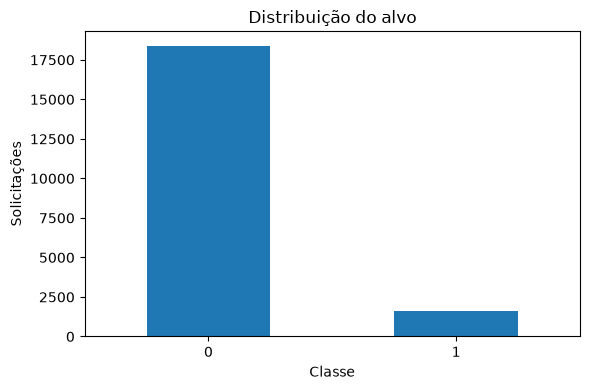

In [4]:
display(validator.compare_targets(tables, preparation.target).round(2))
_ = reporter.plot_target_counts(sample_df[preparation.target])

## 3. Podemos confiar na qualidade desse recorte?

O `HomeCreditData` converte idade de dias negativos para anos, flags de `Y/N` para
`1/0` e remove espaços das categorias. Em seguida, aplica o contrato **Pandera**:
ID único, alvo binário, idade de 18 a 100 anos, valores financeiros positivos e
finitos, filhos não negativos, categorias preenchidas e flags válidas.

**Exceção documentada:** anuidade ausente é permitida. Ela será preenchida no
notebook 02 com a mediana aprendida apenas no treino. Aqui não imputamos nem
normalizamos valores. Uma violação do contrato interrompe a execução.


In [5]:
validated_source = preparation.prepare(raw_df)
prepared_sample = preparation.prepare(sample_df)

display(
    validator.describe_schema({"amostra": prepared_sample}).drop(
        columns=["dataset", "null_rate"]
    )
)
display(validator.duplicated_rows_by_table(tables))
print(
    f"Contrato aprovado: {len(validated_source):,} registros na origem e "
    f"{len(prepared_sample):,} na amostra. Nenhum nulo foi preenchido."
)

,column,dtype,nulls,unique_values
0,SK_ID_CURR,int64,0,20000
1,TARGET,int64,0,2
2,AGE_YEARS,float64,0,11514
3,AMT_INCOME_TOTAL,float64,0,429
4,AMT_CREDIT,float64,0,2454
5,AMT_ANNUITY,float64,2,6011
6,CNT_CHILDREN,int64,0,8
7,NAME_INCOME_TYPE,object,0,8
8,NAME_EDUCATION_TYPE,object,0,5
9,NAME_HOUSING_TYPE,object,0,6


,dataset,duplicate_rows,duplicate_rate
0,origem,0,0.0
1,amostra,0,0.0


Contrato aprovado: 307,511 registros na origem e 20,000 na amostra. Nenhum nulo foi preenchido.


## 4. Como os valores se distribuem?

Os histogramas mostram o perfil de idade, renda e crédito que servirá de contexto
para o drift. A tabela ajuda a comparar valores típicos (`50%`, mediana) e extremos.

A renda usa escala logarítmica apenas no gráfico. Não removemos valores altos
automaticamente: um valor incomum não é, por si só, um dado inválido.


,count,min,50%,95%,max
AGE_YEARS,20000.0,21.03,42.95,63.43,68.94
AMT_INCOME_TOTAL,20000.0,27000.00,144000.00,337500.00,2250000.00
AMT_CREDIT,20000.0,45000.00,513531.00,1350000.00,3312162.00
AMT_ANNUITY,19998.0,2920.50,25033.50,53266.72,225000.00
CNT_CHILDREN,20000.0,0.00,0.00,2.00,19.00


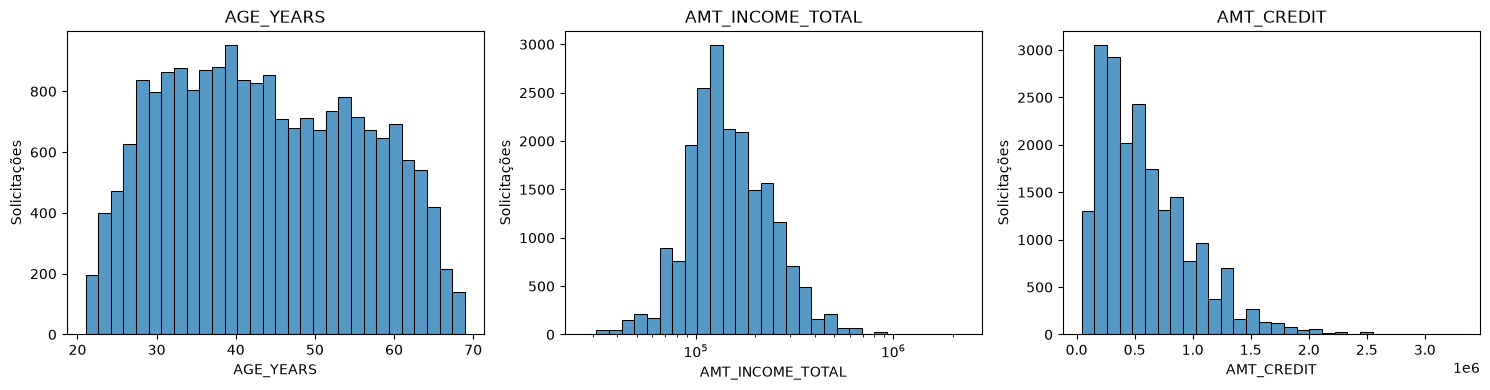

In [6]:
display(
    validator.describe_numeric(prepared_sample, preparation.numeric_features)[
        ["count", "min", "50%", "95%", "max"]
    ].round(2)
)
_ = reporter.plot_histograms(
    prepared_sample,
    ["AGE_YEARS", "AMT_INCOME_TOTAL", "AMT_CREDIT"],
    log_columns=["AMT_INCOME_TOTAL"],
)

## 5. O que a amostra deixa de representar?

Preservar a proporção do alvo não garante a presença de todos os perfis de cliente.
A tabela abaixo mostra **somente categorias presentes na origem e ausentes na
amostra**; uma tabela vazia significa que nenhuma categoria desapareceu.
Categorias presentes com poucos exemplos também exigem cautela na avaliação.


In [7]:
categories = validator.compare_categories(
    tables, preparation.categorical_features + preparation.binary_features
)
missing_categories = categories.loc[
    categories["amostra"].eq(0), ["column", "category", "origem", "amostra"]
]
display(missing_categories)
print(f"Categorias ausentes na amostra: {len(missing_categories)}.")

,column,category,origem,amostra


Categorias ausentes na amostra: 0.


**O que levamos para a próxima etapa:** um recorte conhecido, regras de qualidade
explícitas e uma política para ausências. O notebook **02** repetirá essa seleção,
separará treino, validação, teste e produção e registrará o modelo de referência.
O notebook **03** comparará dados originais e alterados com histogramas sobrepostos
e verificará os alertas do monitor.

**Limites da demonstração:** não temos datas de calendário para representar períodos
reais; as mudanças serão simuladas. Idade, escolaridade e outras variáveis exigem
análise de vieses. O experimento acadêmico não autoriza decisões reais de crédito.
